In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

In [2]:
with h5py.File("../data/Signs_Data_Training.h5", "r") as f:
    X_train = f["train_set_x"][:]
    y_train = f["train_set_y"][:]

with h5py.File("../data/Signs_Data_Testing.h5", "r") as f:
    X_test = f["test_set_x"][:]
    y_test = f["test_set_y"][:]

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(1080, 64, 64, 3) (1080,) (120, 64, 64, 3) (120,)


In [3]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [4]:
from sklearn.model_selection import train_test_split

In [6]:
X_tr,X_val,y_tr,y_val = train_test_split(X_train,y_train,test_size=0.2,stratify=y_train,random_state=42)

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from sklearn.metrics import confusion_matrix, classification_report

In [19]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
])

In [20]:
model = Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax"),
])

In [21]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)            │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,625,926 (6.20 MB)

 Trainable params: 1,625,926 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [23]:
from tensorflow.keras.callbacks import EarlyStopping

In [24]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

In [25]:
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
)

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 146ms/step - accuracy: 0.1898 - loss: 1.8304 - val_accuracy: 0.2269 - val_loss: 1.7422
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 121ms/step - accuracy: 0.3090 - loss: 1.6892 - val_accuracy: 0.4398 - val_loss: 1.4900
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - accuracy: 0.3866 - loss: 1.5081 - val_accuracy: 0.6019 - val_loss: 1.2243
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 121ms/step - accuracy: 0.4502 - loss: 1.3869 - val_accuracy: 0.5185 - val_loss: 1.2086
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 123ms/step - accuracy: 0.4954 - loss: 1.2891 - val_accuracy: 0.6157 - val_loss: 1.0112
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.5475 - loss: 1.2123 - val_accuracy: 0.7500 - val_loss: 0.8644
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 0.5949 - loss: 1.0603 - val_accuracy: 0.8009 - val_loss: 0.7414
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 122ms/step - accuracy: 0.6238 - loss: 1.0031 - val_accu

In [26]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.3f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9667 - loss: 0.0977
Test accuracy: 0.967


In [27]:
y_pred = model.predict(X_test).argmax(axis=1)
print(confusion_matrix(y_test, y_pred))

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step
[[20  0  0  0  0  0]
 [ 0 20  0  0  0  0]
 [ 0  3 17  0  0  0]
 [ 0  0  0 20  0  0]
 [ 0  0  0  1 19  0]
 [ 0  0  0  0  0 20]]


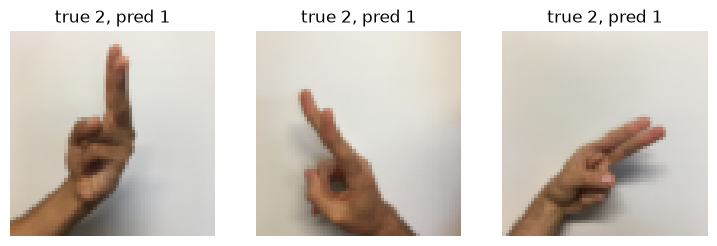

In [28]:
import matplotlib.pyplot as plt

wrong = np.where((y_test == 2) & (y_pred == 1))[0]
fig, axes = plt.subplots(1, len(wrong), figsize=(3 * len(wrong), 3))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(X_test[i])
    ax.set_title(f"true 2, pred 1")
    ax.axis("off")
plt.show()

In [29]:
model.save("../model/sign_cnn_augmented.keras")